In [1]:
import scipy as sp
import numpy as np
import matplotlib.pyplot as plt

# Bisection for finding a root--very import method in economics

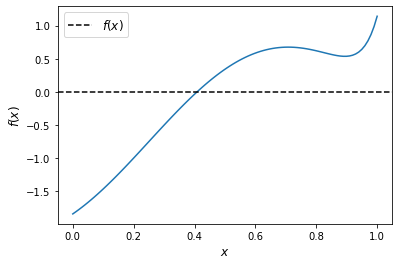

In [2]:
f = lambda x: np.sin(4 * (x - 1/4)) + x + x**20 - 1
x = np.linspace(0, 1, 100)

fig, ax = plt.subplots()
ax.plot(x, f(x))
ax.axhline(ls='--', c='k', label='$f(x)$')
ax.set_xlabel('$x$', fontsize=12)
ax.set_ylabel('$f(x)$', fontsize=12)
ax.legend(fontsize=12)
plt.show()

In [3]:
from scipy.optimize import bisect
bisect(f,0.2, 0.9)

0.408293504278663

# Understanding prices across time

Consider a two-period model of consumer choice.  In a static framework, we could label the good on the horizontal axis "peanut butter" and that on the vertical axis "jelly".  Then the budget line, which has the slope $-p_1/p_2$ would record the tradeoff between peanut butter and jelly.  In particular, if one gave up a unit of peanut butter, one has $p_1$ extra dollars with which one could buy $p_1/p_2$ more units of jelly.

Likewise, if one has $m$ dollars of money income, then the intercept on the horizonatl acis is $m/p_1$ and that on the vertical axis is $m/p_2$.  So the slope of the budget line is again $-p_1/p_2$, where again $p_1$ is the price of the first good, traditionally graphed on the x-axis, the first axis.

In a two-period model, the budget constraint would have slope $-(1+r)$ because $m$ dollars today translate into $m(1+r)$ dollars next period.  Thus

$$
p_2 = \dfrac{p_1}{1+r},
$$

the normal state of affairs would have $p_2 < p_1$ if the real interest rate were positive.

The most important point of today's lecture is that one can view goods as Arrow and Debreu did: they are dated and state-contingent commodities.  Thus peanut butter available today is different from peanut butter available tomorrow.  Likewise, peanut butter avaialble tomorrow in the state of the world where there is a big earthquake in San Luis Obispo is different from the same commoidity available tomorrow if there is no big eqrthquake here.  In the rest of today's lecture, we will forgo consideration of different states of nature and concentrate only on commodities available across time.

Since this is a course in macroeoconomics, we will think of an infinite stream of a homogenous consumption good available at times $t \in \{0, 1, \dots\}$.  Such a consumption stream will be denoted:

$$
c = (c_0, c_1, \dots )
$$

and its corresponding vector of prices is:

$$
p = (p_0, p_1, \dots )
$$

It is conventional to impose the normalization $p_0=1$.  Then $p_1$ is the present price of consumption available at time $t=1$, and we know that 

$$
p_1=\dfrac{1}{1+r_{0,1}},
$$

where I have been careful to indicate that the real interest rate is that occuring from $t=0$ to $t=1$.  <i>Every real interest rate is an intertemporal price between two periods.</i>

We can push this insight further:

$$
p_t = \prod_{i=0}^{t-1} \dfrac{1}{1+r_{i,i+1}},
$$

which formula shows that $p_t$ is the price of consumption at time $t$ discounted appropriately.  If all but finitely many of the real interest rates are strictly positive, then $\lim_{t \to \infty} p_t = 0.$

This notation allows us to evaluate the present value of an infinite stream of income appropriately.  Let $y=(y_0,y_1,\dots)$ be such a stream.  Then

$$
w = p \cdot y = \sum_{t=0}^\infty p_t y_t
$$

is its present discounted value, and we have simply assumed that this infinite sum exists.

# Inter-temporal choice

Let wealth $w$ and the gross real interest rate be given.  Wealth should be though of as the present value of the stream income

$$
w = \sum_{i=0}^T (1+r)^{-i} y_i
$$

where $y_i$ is the income stream in period $i$, $T$ is the planning horizon, and real interest rates are assumed to be constant at $r$.  For the moment, assume that $T=1$

The agents's utility function is given by:

$$
U(c_0,c_1,\dots) = \sum_{i=0}^T \beta^i u(c_i)
$$

where $\beta$ is the subjective discount factor.  Utility $U(\cdot)$ depends upon the entire steram of consumption but felicity $u(\cdot)$ captures momentary well-being from current consumption.  That function is stationary, and preferences are additively separable across time.  So one's marginal rate of subsitution between lunch and dinner is independent of how large one's breakfast was.  The felicity function $u(\cdot)$ is often assumed to be:

$$
u(c) = \dfrac{c^{1-\rho}}{1-\rho}~~~\rho \ge 0
$$
The parameter $\rho$ captures the inter-temporal elasticity of substition.  When $\rho=1$, the felicity function is:

$$
u(c) = log(c)
$$

When both $c_0$ and $c_1$ are strictly positive, then 

$$
(1+r) = \dfrac{p_0}{p_1} = \dfrac{\partial U(c_0,c_1)/\partial c_0}{\partial U(c_0,c_1)/\partial c_1}= \dfrac{1}{\beta}\left(\dfrac{c_0}{c_1}\right)^{-\rho}
$$

Thus

$$
log(1+r) = -log(\beta) -\rho\left[log(c_0) - log(c_1)\right]
$$

and

$$
dr  \approx  -\rho\left[dc_0/c_0 - dc_1/c_1\right]
$$

This equation shows that $1/\rho$ is the intertemporal elasticity of substitution.  A small increas in the real interest rate $r$ will decrease the ratio of current to future consumption by $dr/\rho$.  When $\rho = 0$, then an small increase in the interest rate will induce a lot of extra savings, and when $\rho = \infty$, savings are insensitive to the real interest rate.

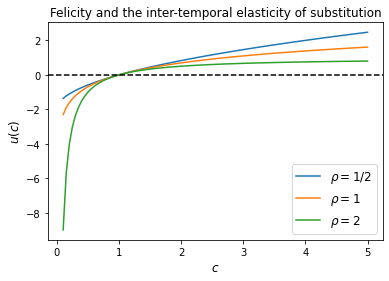

In [4]:
def u(c):
    if rho == 1:
        u = np.log(c) 
    else: 
        u =(c**(1-rho)-1)/(1-rho)
    return u

x = np.linspace(0.1, 5, 100)
fig, ax = plt.subplots()
rho = 1/2
ax.plot(x, u(x),label= r'$\rho = 1/2$')
rho = 1
ax.plot(x, u(x), label=r'$\rho = 1$') 
rho = 2
ax.plot(x, u(x), label=r'$\rho = 2$')
ax.legend()
ax.axhline(ls='--', c='k')
ax.set_xlabel('$c$', fontsize=12)
ax.set_ylabel('$u(c)$', fontsize=12)
ax.set_title('Felicity and the inter-temporal elasticity of substitution')
ax.legend(fontsize=12)
plt.show()

Text(5.099078232223382, 5.1459678560660596, 'x')

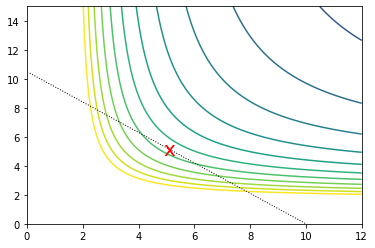

In [5]:
#budget equation
interest_rate = 0.05
wealth = 10
#preference parameters
rho = 2
beta = 0.97

def U(c):
    if rho == 1:
        u = log(c[0]) + beta*log(c[1])
    else: 
        u =(c[0]**(1-rho)+beta*c[1]**(1-rho))/(1-rho)
    return -u

cons = ({'type': 'ineq',
         'fun' : lambda x: np.array([wealth - x[0] - x[1]/(1+interest_rate)])})
    
bnds = ((0.5, 10), (0.5, 10))
x0 = [2.5, 2.5]

from scipy import optimize as opt
cx = opt.minimize(U, x0, bounds=bnds, constraints=cons)
cx

xend = 12
yend = 15
curvespacing = 0.04

x = np.linspace(0.1, xend, 100)
y = np.linspace(0.1, yend, 100)
X, Y = np.meshgrid(x, y)
Z = U(np.vstack([X.ravel(), Y.ravel()])).reshape((100,100))
plt.contour(X, Y, Z, np.arange(0,0.6,curvespacing));
plt.plot(x, (wealth-x)*(1+interest_rate), 'k:', linewidth=1)
#plt.fill([4,4,6,6], [4,6,6,4], alpha=0.2)
plt.axis([0,xend,0,yend])
plt.text(cx['x'][0], cx['x'][1], 'x', va='center', ha='center', size=20, color='red')



# Classic savings problem

The agent faces this choice problem:

$$
\begin{array}{c}
\text{choose}~~(c_0,c_1,k_1,k_2) \\
\text{to maximize}\\
U(c_0,c_1) \\
\text{subject to}\\
c_0 + k_1 \le f(k_0) \\
c_1 + k_2 \le f(k_1)\\
k_2 \ge 0 \\
k_0~~\text{given}
\end{array}
$$

We will assume now that $U(c_0,C_1) = u(c_0) + \beta u(c_1)$

The relevant Lagrangean is:

$$
L(c_0,c_1,k_1,k_2,\lambda_1, \lambda_2,\lambda_3) = u(c_0)+ \beta u(c_1) - \lambda_1[c_0 + k_1 -f(k_0)] - \lambda_2[c_1 + k_2 -f(k_1)] -\lambda_3 k_2
$$

The first-order necessary conditions are:

$$
\begin{array}{l c}
\text{w.r.t}~~c_0: & u'(c_0) = \lambda_1 \\
\text{w.r.t}~~c_1: & \beta u'(c_1) = \lambda_2 \\
\text{w.r.t}~~k_1: & \lambda_1 = \lambda_2 f'(k_1) \\
\text{w.r.t}~~k_2: & \lambda_2 = \lambda_3 \\
\text{w.r.t}~~\lambda_1: & c_0 + k_1 - f(k_0) \ge 0\\
\text{w.r.t}~~\lambda_2: & c_1 + k_2 - f(k_1) \ge 0\\
\text{w.r.t}~~\lambda_3: & k_2\ge 0\\
\end{array}
$$

If the marginal felicity of consumption is always positive, we know that $u'(c_0) > 0$ and $u'(c_1)>0$.  Then if the subjective discount factor $\beta \ne 0$, we see that all three of the Lagrange multipliers will be strictly positive.  Then we can conclude that $k_2 = 0$, and the agent won't leave any capital lying around when she perishes.  Thus $c_1 = f(k_1)$.  We only need to find values for $c_0$ and $k_1$.  Finding the right values for these two variables is equivalent to answering the question: How much should the agent save in period 0, knowing that she has $f(k_0)$ units of output at hand?

This question is at the heart of a modern approach to macroeconomics.  We know that

$$
\dfrac{\beta u'(c_1)}{u'(c_0)} = \dfrac{\lambda_2}{\lambda_1} =\dfrac{1}{f'(k_1)}
$$

This equation implies:

$$
1 = \dfrac{\beta u'(c_1) f'(k_1)}{u'(c_0)}.
$$

In other words, the agent will chose to save and invest $k_1$ so that the present discounted value of an extra unit of consumption next period is exactly equal to the marginal feleicity of consumption right now.  The cost of investing is to give up the marginal felicity of consuming right now.  The benefit of saving is the product of three terms: (1) the discount factor; (2) the marginal felicity of consumption next period; and (3) the marginal efficiency of investment $f'(k_1)$ right now.  

In the particular case where

$$
u(c) = \dfrac{c^{1-\rho}-1}{1-\rho},
$$

marginal felcity is simply:

$$
u'(c) = c^{-\rho}
$$

and the first-order necessary condition imply that

$$
1 = \dfrac{\beta c_1^{-\rho} f'(k_1)}{c_0^{-\rho}}.
$$

Hence:

$$
c_1 = c_0 \left[\beta f'(k_1)\right]^{1/\rho}
$$

The marginal product of capital is the gross real interest rate; one extra unit of investment today will yield $1+r$ units of output next period.  Then this expression is:

$$
c_1 = c_0 \left[\beta (1+r)\right]^{1/\rho}.
$$

Higher real interest rates induce more future consumption because people save; they consume less now and more in the future.  Savings increases rapidly with the real interest rate when $\rho \approx 0$.  Consumption is flat across time only when $\beta = (1+r)^{-1}$.

In [6]:

#cons = ({'type': 'eq',
 #        'fun' : lambda x: np.array([x[0]**3 - x[1]]),
  #       'jac' : lambda x: np.array([3.0*(x[0]**2.0), -1.0])},
   #     {'type': 'ineq',
    #     'fun' : lambda x: np.array([x[1] - (x[0]-1)**4 - 2])})

#cons = ({'type': 'ineq',
         #'fun' : lambda x: np.array([wealth - x[0] - x[1]/(1+interest_rate)])})
    
#bnds = ((0.5, 10), (0.5, 10))
#x0 = [2.5, 2.5]

In [7]:
K0 = 5  #intial capital
alpha = 0.33 # capital's share
A = 6 # Total factor productivity
Y1=A*K0**alpha  #GDP at time 1

#preference parameters
rho = 0.9 #elasticity of substitution
beta = 0.9 #discount factor

def f(c):
    """
    This is the utility function for a two-period model
    """
    if rho == 1:
        u = np.log(c[0]) + beta*np.log(c[1])
    else: 
        u =(c[0]**(1-rho)+beta*c[1]**(1-rho))/(1-rho)
    return -u

def MRS(c):
    """
    This is the utility function for a two-period model
    """
    if rho == 1:
        MRS = [1/c[0], beta/c[1]]
    else: 
        MRS =[c[0]**(-rho), beta*c[1]**(-rho)]
    return MRS

x0 = [5, 5]
bnds = ((0.5, 200), (0.5, 200))
cons = ({
    'type': 'eq',
    'fun' : lambda x: np.array([x[1] - A*(Y1-x[0])**alpha]),
    'jac' : lambda x: np.array([A*alpha*(Y1-x[0])**(alpha-1),1])
})
from scipy import optimize as opt
cx = opt.minimize(f, x0, bounds=bnds, constraints=cons)
cx



     fun: -23.362902875383163
     jac: array([-0.15624404, -0.13942003])
 message: 'Optimization terminated successfully'
    nfev: 25
     nit: 8
    njev: 8
  status: 0
 success: True
       x: array([7.86640863, 7.94152298])

The present price vector is [1.   0.89]
Gross interest rates are 1.121
The consumption plan is [7.87 7.94]
Savings is 2.34


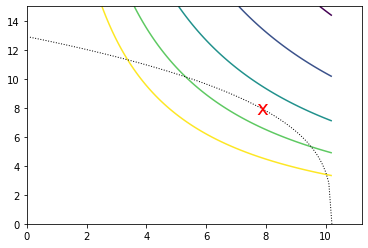

In [8]:
xend = Y1
yend = 15
curvespacing = 0.4

x = np.linspace(0.1, xend, 100)
y = np.linspace(0.1, yend, 100)
X, Y = np.meshgrid(x, y)
Z = f(np.vstack([X.ravel(), Y.ravel()])).reshape((100,100))
plt.contour(X, Y, Z, np.arange(cx['fun']-1,cx['fun']+1,curvespacing));
plt.plot(x, A*(Y1 - x)**alpha, 'k:', linewidth=1)
plt.axis([0,xend+1,0,yend])
#[0, 3, 0, 3]
plt.text(cx['x'][0], cx['x'][1], 'x', va='center', ha='center', size=20, color='red')


c=[cx['x'][0],cx['x'][1]]
prices=MRS(c)
prices = prices/prices[0]
print('The present price vector is', np.round(prices,2))
print('Gross interest rates are',np.round(1/prices[1],3))
print('The consumption plan is',np.round(c,2))
print('Savings is',round(Y1-c[0],2))
